In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [ ]:
df=pd.read_csv('dataset/bank.csv')

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [5]:
df.shape

(8912, 17)

In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [7]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

In [8]:
df.isnull().sum()

age            0
job            7
marital      169
education     27
default        4
balance       13
housing       13
loan          30
contact       31
day           19
month         28
duration       7
campaign       8
pdays        145
previous       3
poutcome       0
deposit        9
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.dropna(subset=['deposit','default','previous','campaign','job','duration','contact','housing'])

In [11]:
from sklearn.impute import SimpleImputer

impute = SimpleImputer(strategy='most_frequent')

df[['marital','loan','education','month']] = impute.fit_transform(
    df[['marital','loan','education','month']]
)

In [12]:

impute = SimpleImputer(strategy='mean')

df[['pdays','day','balance']] = impute.fit_transform(
    df[['pdays','day','balance']]
)

In [13]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='deposit', y='age')
plt.title('age vs deposit')
plt.tight_layout()
plt.show()

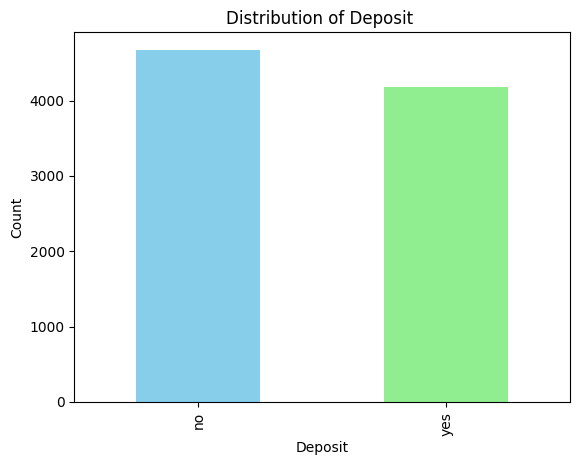

In [17]:
df['deposit'].value_counts().plot(kind='bar', color=['skyblue', 'lightgreen'])
plt.title('Distribution of Deposit ')
plt.ylabel('Count')
plt.xlabel('Deposit')
plt.show()

In [18]:
from sklearn.preprocessing import LabelEncoder

In [19]:
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

In [20]:
X = df.drop(columns=['deposit'])
y = df['deposit']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

results = []

In [24]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": acc})

    print(f"{name}")
    print(classification_report(y_test, y_pred))
    print("="*40)
results_df = pd.DataFrame(results)
print("\n📊 Model Comparison Table:")
print(results_df)

Logistic Regression
              precision    recall  f1-score   support

           0       0.81      0.82      0.81       965
           1       0.78      0.77      0.78       806

    accuracy                           0.80      1771
   macro avg       0.80      0.80      0.80      1771
weighted avg       0.80      0.80      0.80      1771

KNN
              precision    recall  f1-score   support

           0       0.79      0.82      0.80       965
           1       0.77      0.73      0.75       806

    accuracy                           0.78      1771
   macro avg       0.78      0.78      0.78      1771
weighted avg       0.78      0.78      0.78      1771

Naive Bayes
              precision    recall  f1-score   support

           0       0.81      0.71      0.76       965
           1       0.70      0.80      0.74       806

    accuracy                           0.75      1771
   macro avg       0.75      0.75      0.75      1771
weighted avg       0.76      0.75     

In [25]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Lasso": LogisticRegression(penalty='l1', solver='liblinear'),
    "Ridge": RidgeClassifier(),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVC(kernel='rbf', C=1),
    "Decision Tree": DecisionTreeClassifier(criterion='gini', max_depth=10),
    "Random Forest": RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [26]:
clf_results = []
clf_preds = {}

for name, model in clf_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    clf_preds[name] = y_pred

    clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

clf_results_df = pd.DataFrame(clf_results).sort_values(by='F1 Score', ascending=False)
clf_results_df.reset_index(drop=True, inplace=True)
clf_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,HistGradientBoosting,0.866177,0.831972,0.884615,0.857486
1,XGBoost,0.865048,0.836299,0.874690,0.855064
2,LightGBM,0.862225,0.831368,0.874690,0.852479
3,CatBoost,0.854884,0.824852,0.864764,0.844337
4,Random Forest,0.849238,0.815944,0.863524,0.839060
5,GradientBoosting,0.849802,0.821429,0.856079,0.838396
6,ExtraTrees,0.847544,0.816038,0.858561,0.836759
7,Bagging,0.847544,0.818290,0.854839,0.836165
8,SVM,0.818182,0.784038,0.828784,0.805790
9,Decision Tree,0.811406,0.804124,0.774194,0.788875


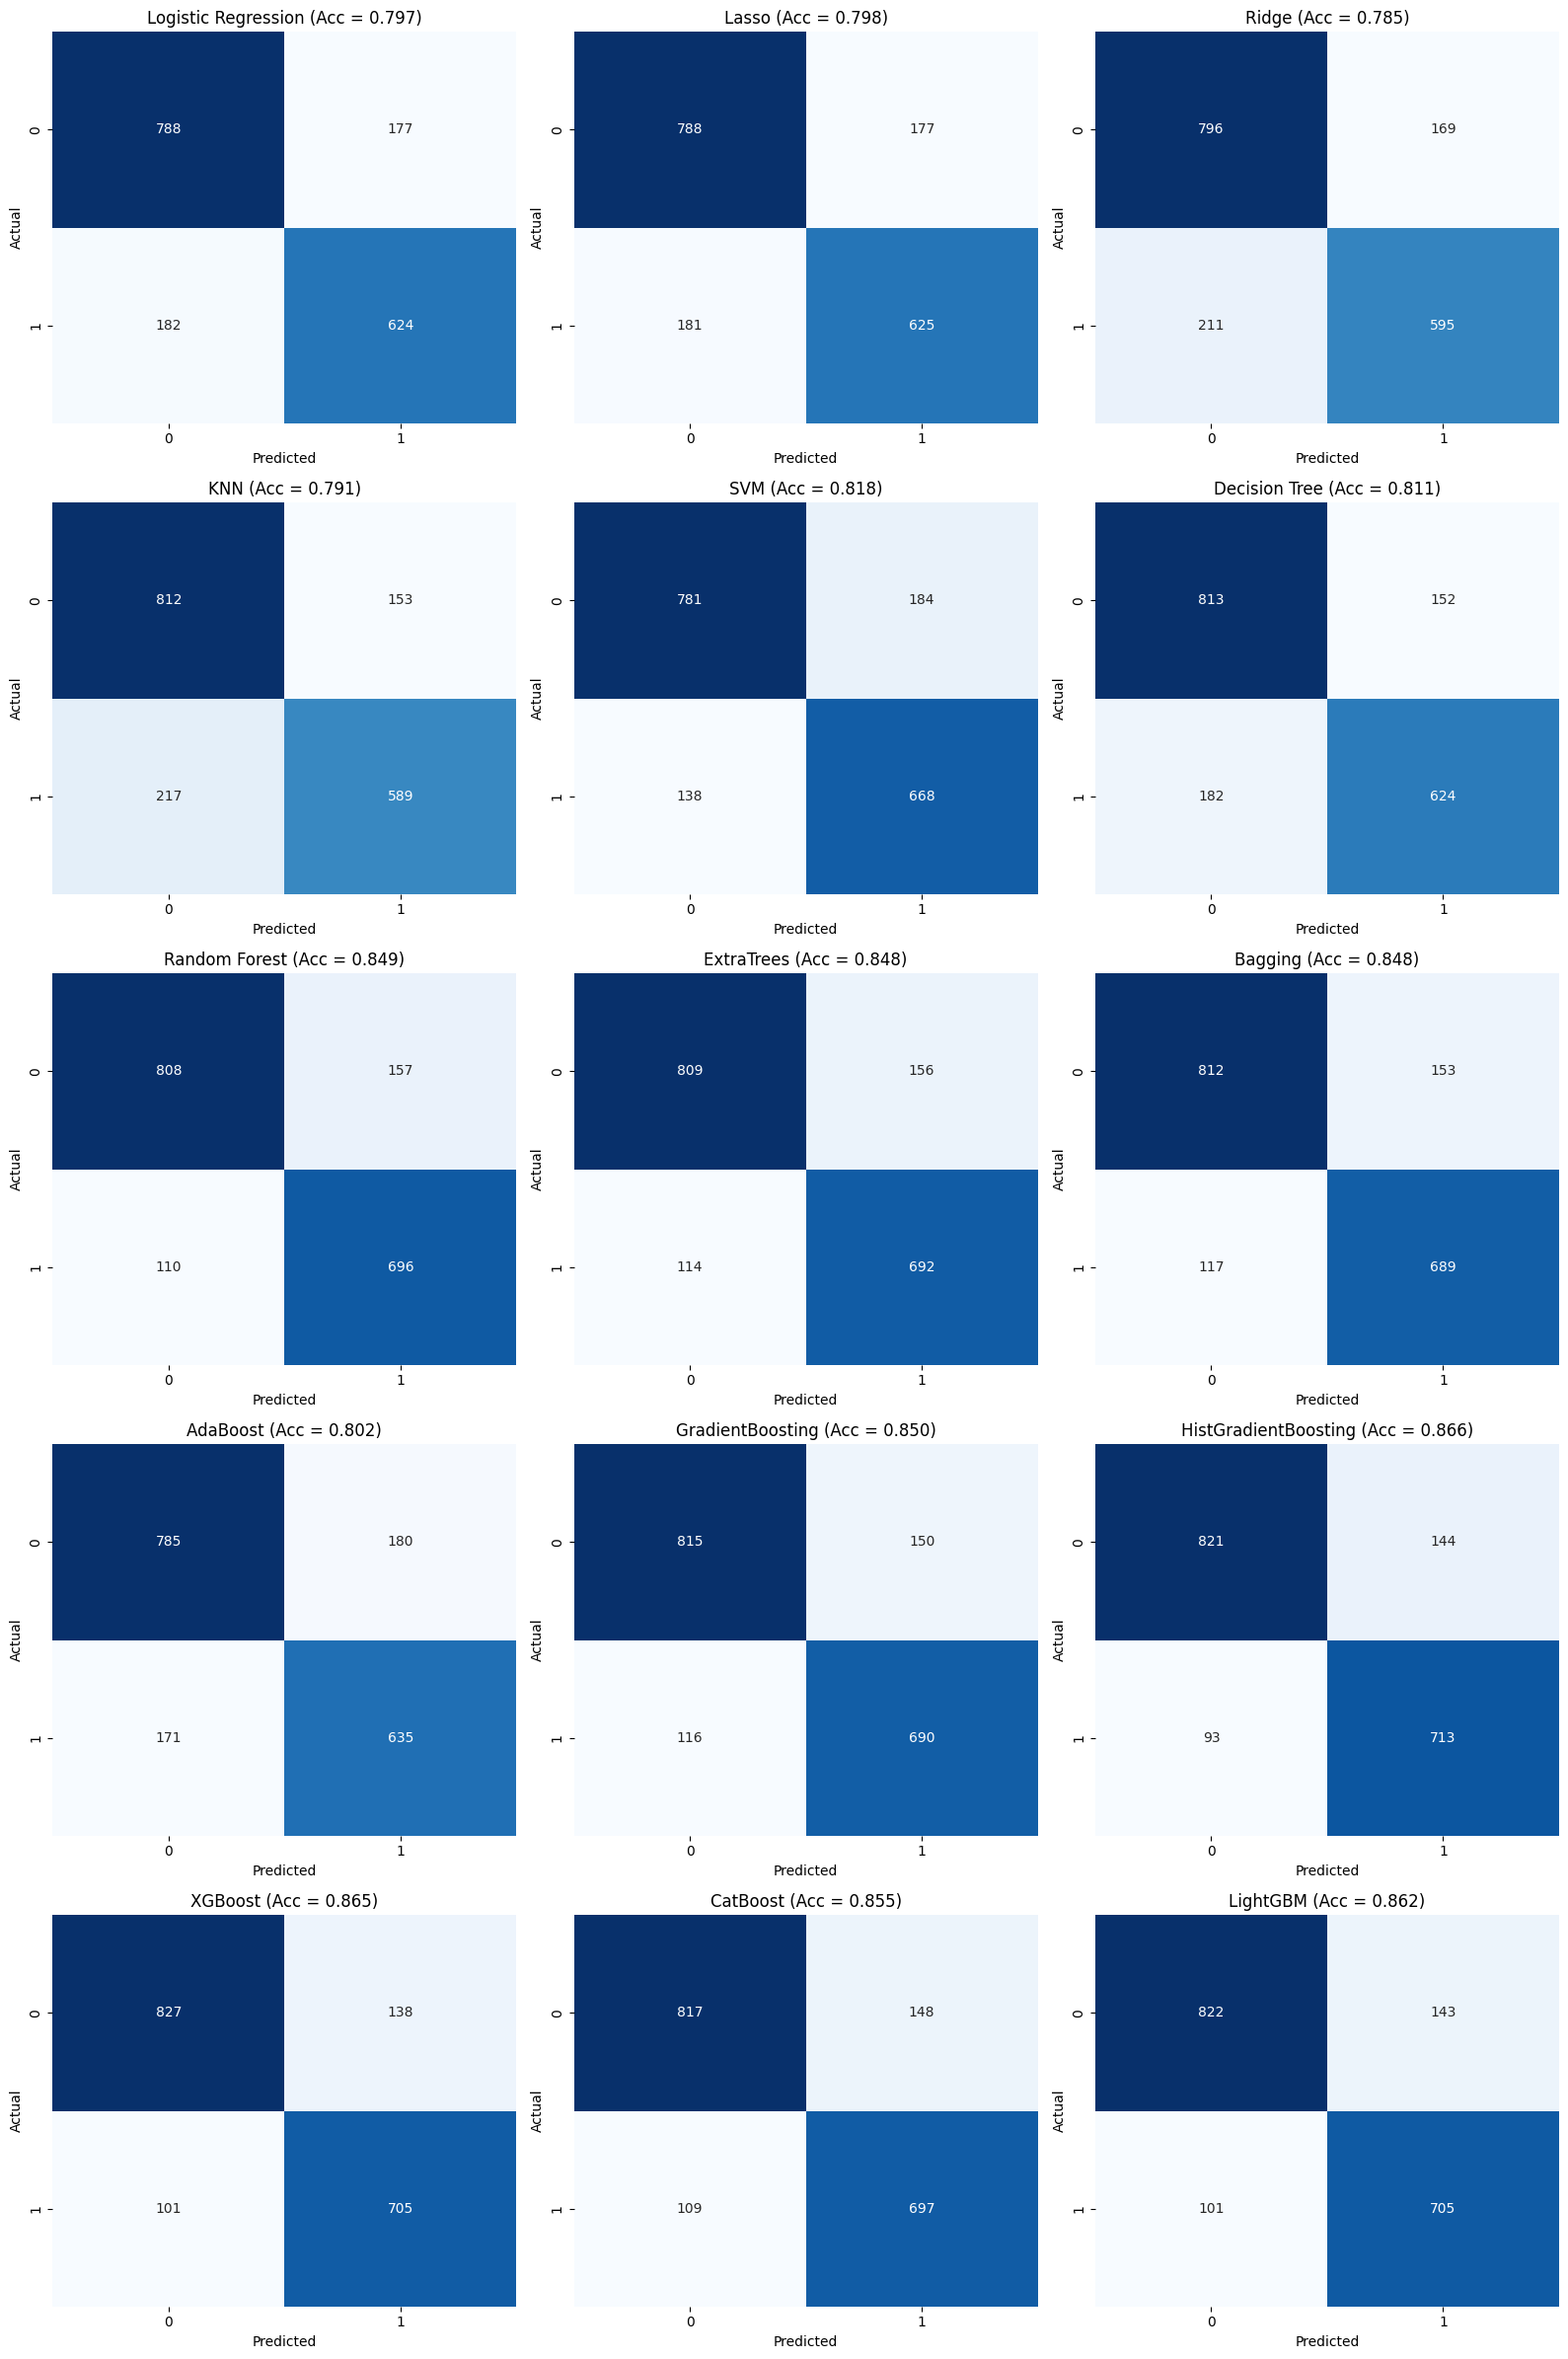

In [27]:
fig, axes = plt.subplots(5, 3, figsize=(16, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(clf_preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i])
    axes[i].set_title(f"{name} (Acc = {accuracy_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Model comparison (F1)

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=clf_results_df, x='F1 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('F1 Score Comparison')
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in clf_models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='f1', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV F1': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV F1', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Logistic Regression": {"C": [0.1, 1, 10]},
    "Lasso": {"C": [0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [0.1, 1, 10]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(clf_models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='f1', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

base_model = clone(clf_models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p, zero_division=0),
                 'Recall': recall_score(y_test, p, zero_division=0),
                 'F1': f1_score(y_test, p, zero_division=0)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

y_pred = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
from sklearn.metrics import confusion_matrix

if hasattr(best_model, 'predict_proba'):
    scores = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    scores = best_model.decision_function(X_test_scaled)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- Accuracy = {acc:.3f}: {acc*100:.1f}% of all predictions are correct.")
print(f"- Precision = {prec:.3f}: when the model predicts the positive class, it is right {prec*100:.1f}% of the time ({fp} false alarms).")
print(f"- Recall = {rec:.3f}: the model finds {rec*100:.1f}% of the real positive cases and misses {fn}.")
print(f"- F1 = {f1:.3f}: the balance between precision and recall.")
print(f"- ROC-AUC = {roc_auc_score(y_test, scores):.3f}: the chance that a random positive case is ranked above a random negative one.")
print(f"- Average Precision (PR curve) = {average_precision_score(y_test, scores):.3f}: more reliable than accuracy when the classes are imbalanced.")
if rec < prec:
    print("- Recall is lower than precision: the model is careful but misses some positive cases.")
else:
    print("- Precision is lower than recall: the model catches most positive cases but raises some false alarms.")